# Phase 1: Data Exploration for Drug Discovery VAE
This notebook focuses on loading the ZINC dataset, exploring the chemical properties, and visualizing the molecules.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import Draw

import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style="whitegrid")

In [2]:
# Load the dataset
# Using relative path because this notebook is inside the 'notebooks' folder
data_path = '../data/raw/250k_rndm_zinc_drugs_clean_3.csv'
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (249455, 4)


,smiles,logP,qed,SAS
0,CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1\n,5.05060,0.702012,2.084095
1,C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1\n,3.11370,0.928975,3.432004
2,N#Cc1ccc(-c2ccc(O[C@@H](C(=O)N3CCCC3)c3ccccc3)...,4.96778,0.599682,2.470633
3,CCOC(=O)[C@@H]1CCCN(C(=O)c2nc(-c3ccc(C)cc3)n3c...,4.00022,0.690944,2.822753
4,N#CC1=C(SCC(=O)Nc2cccc(Cl)c2)N=C([O-])[C@H](C#...,3.60956,0.789027,4.035182


## Analyze SMILES Lengths
The length of the SMILES strings is important for configuring our Neural Network sequence length.

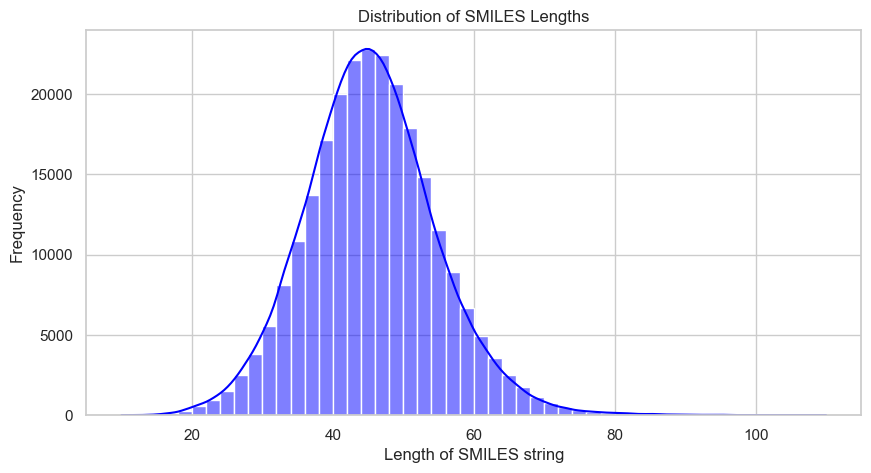

Max SMILES length: 110
Average SMILES length: 45.31


In [3]:
# Calculate length of each SMILES string
if 'smiles' in df.columns:
    smiles_col = 'smiles'
else:
    # Fallback to the first column if named differently
    smiles_col = df.columns[0]

df['smiles_length'] = df[smiles_col].apply(lambda x: len(str(x)))

plt.figure(figsize=(10, 5))
sns.histplot(df['smiles_length'], bins=50, kde=True, color='blue')
plt.title('Distribution of SMILES Lengths')
plt.xlabel('Length of SMILES string')
plt.ylabel('Frequency')
plt.show()

print(f"Max SMILES length: {df['smiles_length'].max()}")
print(f"Average SMILES length: {df['smiles_length'].mean():.2f}")

## Analyze Chemical Properties (QED and logP)
If the dataset includes drug-likeness (QED) and solubility (logP), let's plot their distributions.

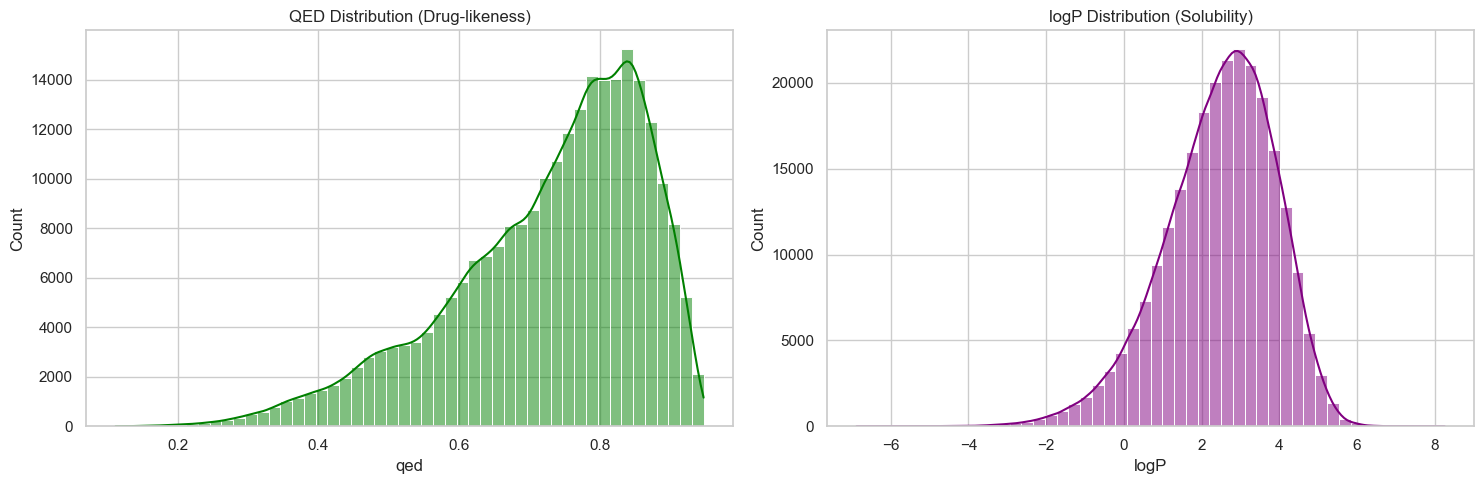

In [4]:
# Check for QED and logP columns
available_cols = df.columns.str.lower()

if 'qed' in available_cols and 'logp' in available_cols:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # QED Plot
    qed_col = df.columns[available_cols == 'qed'][0]
    sns.histplot(df[qed_col], bins=50, kde=True, ax=axes[0], color='green')
    axes[0].set_title('QED Distribution (Drug-likeness)')
    
    # logP Plot
    logp_col = df.columns[available_cols == 'logp'][0]
    sns.histplot(df[logp_col], bins=50, kde=True, ax=axes[1], color='purple')
    axes[1].set_title('logP Distribution (Solubility)')
    
    plt.tight_layout()
    plt.show()
else:
    print("QED or logP columns not found in dataset. We will calculate them later if needed.")

## Visualize Sample Molecules
Let's draw some of the molecules using RDKit to see what we are working with!

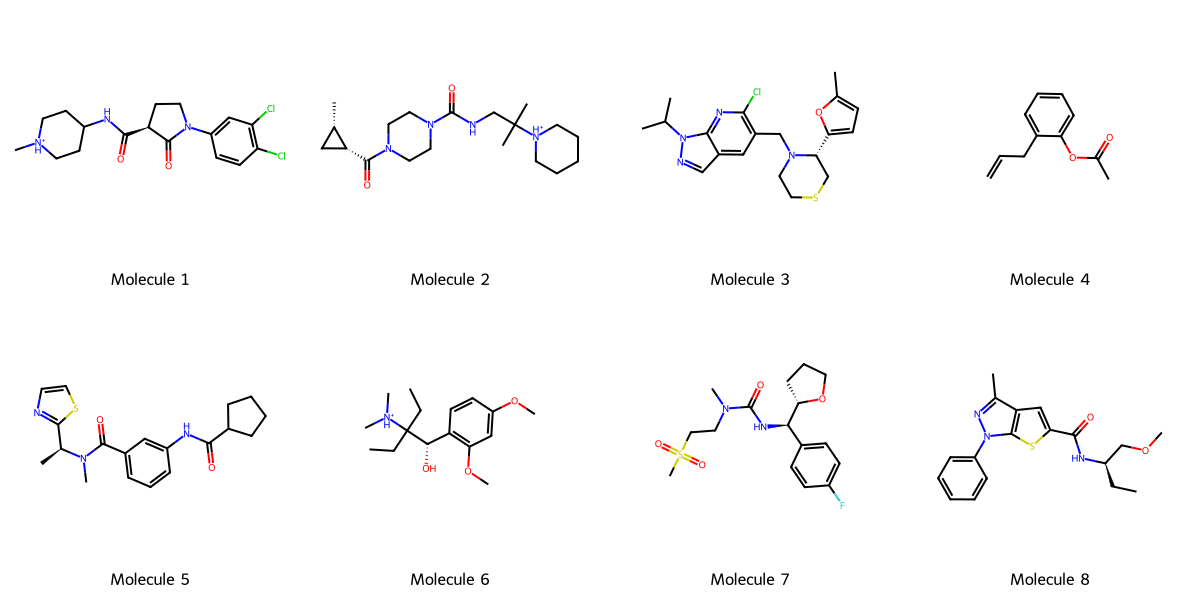

In [5]:
# Pick 8 random SMILES strings
sample_smiles = df[smiles_col].sample(8, random_state=42).tolist()

# Convert SMILES to RDKit Molecule objects
molecules = [Chem.MolFromSmiles(str(s)) for s in sample_smiles]

# Draw a grid image of the molecules
img = Draw.MolsToGridImage(molecules, molsPerRow=4, subImgSize=(300, 300), legends=[f"Molecule {i+1}" for i in range(8)])
img